PART A: Gaussian Naive Bayes on Iris
Accuracy: 0.9111

Classification report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45

5-fold CV accuracy: 0.9533 (+/- 0.0267)

Class priors: {np.str_('setosa'): np.float64(0.333), np.str_('versicolor'): np.float64(0.333), np.str_('virginica'): np.float64(0.333)}

Feature means per class:
             sepal length (cm)  sepal width (cm)  petal length (cm)  \
setosa                  4.989             3.426              1.486   
versicolor              5.949             2.731              4.237   
virginica               6.683             3.009              5.631   

            petal width (cm)  
setosa                 0

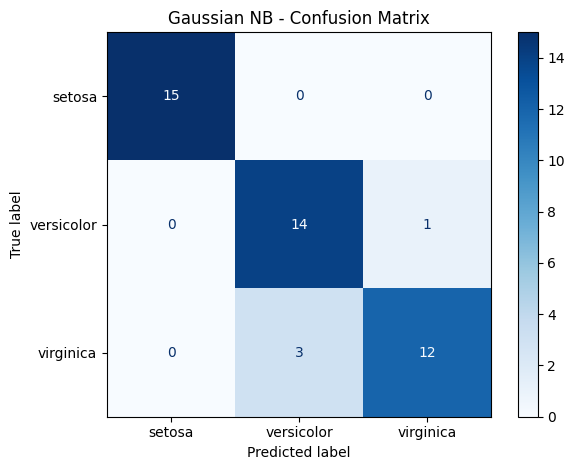


PART B: Multinomial Naive Bayes - text classification
Accuracy: 0.894

Classification report:
                     precision    recall  f1-score   support

     comp.graphics       0.93      0.92      0.92       389
rec.sport.baseball       0.87      0.95      0.91       397
         sci.space       0.89      0.85      0.87       394
talk.politics.misc       0.89      0.85      0.87       310

          accuracy                           0.89      1490
         macro avg       0.89      0.89      0.89      1490
      weighted avg       0.89      0.89      0.89      1490



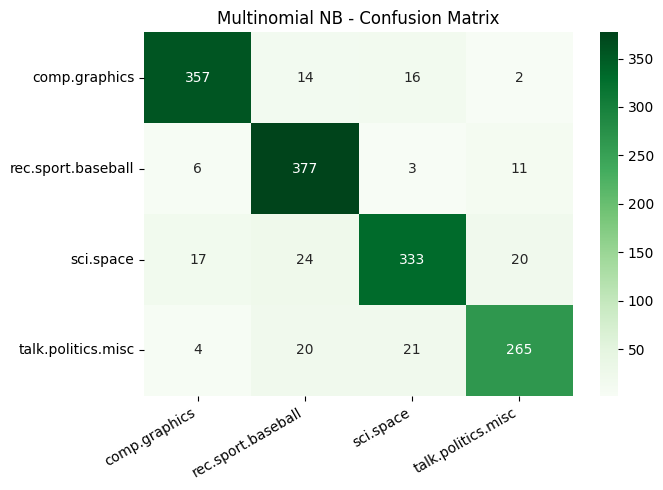

  'NASA launched a new rocket to the moon'  ->  sci.space
  'The pitcher threw a perfect game last night'  ->  rec.sport.baseball
  'The senator proposed a new tax bill'  ->  talk.politics.misc
  'The graphics card renders 3D images quickly'  ->  comp.graphics

PART C: Bernoulli Naive Bayes - binary features
Accuracy: 0.7631

PART D: Naive Bayes from scratch
Scratch implementation accuracy : 0.9111
Scikit-learn GaussianNB accuracy: 0.9111

Conclusion: Naive Bayes assumes features are independent given the class. Despite this simple assumption it works very well on Iris (Gaussian) and on text data (Multinomial/Bernoulli).


In [ ]:
"""
Assignment 4: Apply Naive Bayes classification algorithms.

Parts:
  A. Gaussian Naive Bayes  -> continuous features (Iris dataset)
  B. Multinomial Naive Bayes -> text classification (20 Newsgroups subset)
  C. Bernoulli Naive Bayes   -> binary features (same text, binary word presence)
  D. Naive Bayes from scratch (to show the maths: prior x likelihood)

Install: pip install numpy pandas matplotlib seaborn scikit-learn
Note: Part B downloads the 20 Newsgroups dataset on first run (needs internet).
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris, fetch_20newsgroups
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# ==================================================================
# PART A: Gaussian Naive Bayes (continuous features)
# ==================================================================
print("=" * 60)
print("PART A: Gaussian Naive Bayes on Iris")
print("=" * 60)

iris = load_iris(as_frame=True)
X, y = iris.data, iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

gnb = GaussianNB()
gnb.fit(X_train, y_train)
y_pred = gnb.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:\n",
      classification_report(y_test, y_pred, target_names=iris.target_names))

cv = cross_val_score(GaussianNB(), X, y, cv=5)
print("5-fold CV accuracy: %.4f (+/- %.4f)" % (cv.mean(), cv.std()))

# Class priors and per-class feature means learned by the model
print("\nClass priors:", dict(zip(iris.target_names, gnb.class_prior_.round(3))))
print("\nFeature means per class:\n",
      pd.DataFrame(gnb.theta_, index=iris.target_names, columns=X.columns).round(3))

# Predicted probabilities for the first 5 test samples
proba = pd.DataFrame(gnb.predict_proba(X_test[:5]),
                     columns=iris.target_names).round(4)
print("\nPredicted probabilities (first 5 test samples):\n", proba)

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=iris.target_names).plot(cmap="Blues")
plt.title("Gaussian NB - Confusion Matrix")
plt.tight_layout()
plt.show()

# ==================================================================
# PART B: Multinomial Naive Bayes (text classification)
# ==================================================================
print("\n" + "=" * 60)
print("PART B: Multinomial Naive Bayes - text classification")
print("=" * 60)

categories = ["sci.space", "rec.sport.baseball", "talk.politics.misc", "comp.graphics"]
train = fetch_20newsgroups(subset="train", categories=categories,
                           remove=("headers", "footers", "quotes"))
test = fetch_20newsgroups(subset="test", categories=categories,
                          remove=("headers", "footers", "quotes"))

text_model = make_pipeline(
    TfidfVectorizer(stop_words="english"),
    MultinomialNB(alpha=0.1))          # alpha = Laplace smoothing
text_model.fit(train.data, train.target)
text_pred = text_model.predict(test.data)

print("Accuracy:", round(accuracy_score(test.target, text_pred), 4))
print("\nClassification report:\n",
      classification_report(test.target, text_pred, target_names=test.target_names))

cm = confusion_matrix(test.target, text_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=test.target_names, yticklabels=test.target_names)
plt.title("Multinomial NB - Confusion Matrix")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Predict some new sentences
samples = ["NASA launched a new rocket to the moon",
           "The pitcher threw a perfect game last night",
           "The senator proposed a new tax bill",
           "The graphics card renders 3D images quickly"]
for s, p in zip(samples, text_model.predict(samples)):
    print(f"  '{s}'  ->  {test.target_names[p]}")

# ==================================================================
# PART C: Bernoulli Naive Bayes (binary word presence)
# ==================================================================
print("\n" + "=" * 60)
print("PART C: Bernoulli Naive Bayes - binary features")
print("=" * 60)

bern_model = make_pipeline(
    CountVectorizer(stop_words="english", binary=True),
    BernoulliNB(alpha=0.1))
bern_model.fit(train.data, train.target)
bern_pred = bern_model.predict(test.data)
print("Accuracy:", round(accuracy_score(test.target, bern_pred), 4))

# ==================================================================
# PART D: Gaussian Naive Bayes FROM SCRATCH
# ==================================================================
print("\n" + "=" * 60)
print("PART D: Naive Bayes from scratch")
print("=" * 60)


class NaiveBayesScratch:
    """P(class | x)  ∝  P(class) * Π P(x_i | class), with Gaussian likelihood."""

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        self.classes = np.unique(y)
        self.mean = {c: X[y == c].mean(axis=0) for c in self.classes}
        self.var = {c: X[y == c].var(axis=0) + 1e-9 for c in self.classes}
        self.prior = {c: np.mean(y == c) for c in self.classes}
        return self

    def _log_likelihood(self, c, x):
        # log of Gaussian pdf summed over features
        m, v = self.mean[c], self.var[c]
        return np.sum(-0.5 * np.log(2 * np.pi * v) - ((x - m) ** 2) / (2 * v))

    def predict(self, X):
        X = np.asarray(X)
        preds = []
        for x in X:
            posteriors = [np.log(self.prior[c]) + self._log_likelihood(c, x)
                          for c in self.classes]
            preds.append(self.classes[np.argmax(posteriors)])
        return np.array(preds)


scratch = NaiveBayesScratch().fit(X_train, y_train)
scratch_pred = scratch.predict(X_test)
print("Scratch implementation accuracy :", round(accuracy_score(y_test, scratch_pred), 4))
print("Scikit-learn GaussianNB accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nConclusion: Naive Bayes assumes features are independent given the class. "
      "Despite this simple assumption it works very well on Iris (Gaussian) "
      "and on text data (Multinomial/Bernoulli).")